# Diabetes Risk Factor Analysis

This notebook explores which patient characteristics are associated with diabetes status in the PIMA dataset of 768 patients.

**Research questions**
1. How are the patient characteristics distributed, and how do they differ between patients with and without diabetes?
2. Is mean plasma glucose different between the two outcome groups?
3. Is obesity (BMI ≥ 30) associated with diabetes status?

**How to run:** put your dataset in the same folder as this notebook (in Colab, upload it when asked), then choose Runtime → Restart session and run all (Colab) or **Kernel → Restart Kernel and Run All Cells (Jupyter / VS Code). Run cells in order, top to bottom.

**Workflow:** Setup → Data Source → Data Loading → Data Validation → Data Preparation → Analysis → Results → Conclusions.

## Setup and Environment

The analysis needs Python 3.9+ and pandas (2.0+), numpy (1.24+), matplotlib (3.7+) and scipy (1.11+)

These packages are preinstalled for colab. For other IDEs, the next cell installs anything that is missing and works in Colab, Jupyter and VS Code.

The cell also sets a random seed of 42 so that every random operation gives the same result on every run.

In [37]:
from importlib import metadata

import sys
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats

requirements = {"pandas": (2, 0), "numpy": (1, 24), "matplotlib": (3, 7), "scipy": (1, 11)}

def is_ok(package, minimum):
    try:
        installed = tuple(int(x) for x in metadata.version(package).split(".")[:2])
    except (metadata.PackageNotFoundError, ValueError):
        return False
    return installed >= minimum

to_install = [f"{p}>={'.'.join(map(str, v))}" for p, v in requirements.items() if not is_ok(p, v)]
if to_install:
    get_ipython().run_line_magic("pip", "install -q " + " ".join(f'"{r}"' for r in to_install))
    print("Installed:", to_install, "- if imports fail below, restart the session and run all again.")
else:
    print("All required packages are already installed.")


SEED = 42
random.seed(SEED)
np.random.seed(SEED)

All required packages are already installed.


## Data Source

The project uses the diabetes example dataset provided with the analysis.

* **File:** `Example Dataset_Diabetes.csv` (768 rows, 9 columns)
* **Origin:** **Pima Indians Diabetes Database** from the U.S. National Institute of Diabetes and Digestive Kidney Diseases (NIDDK), available through the UCI Machine Learning Repository (Smith et al., 1988). The patients are women aged 21 or older of Pima Indian heritage.


To load your own data, make the CSV available using one of these:
* **Jupyter / VS Code:** save it in the same folder as the notebook.
* **Google Colab:** upload it with the Files panel or run the next cell, which opens an upload dialog.

In [38]:
DATA_FILE = "Example Dataset_Diabetes.csv"

def load_data(filename=DATA_FILE):
    # Look in the notebook folder, the course-repository folder, and Colab's /content folder
    for folder in [Path("."), Path("Reproducibility Exercise"), Path("/content")]:
        if (folder / filename).exists():
            print("Loading:", (folder / filename).resolve())
            return pd.read_csv(folder / filename)
    # In Colab, ask the user to upload the file
    if "google.colab" in sys.modules:
        from google.colab import files
        files.upload()
        return pd.read_csv(filename)
    raise FileNotFoundError(f"'{filename}' not found. Place it next to this notebook and re-run.")

df = load_data()
df.head()

Loading: /content/Example Dataset_Diabetes.csv


,Pregnancies,Glucose,D_BP,Skin_Thickness,Insulin,BMI,Pedigree,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## Initial Data Review

Before analysing, confirm that the expected dataset was loaded. The checks below stop the notebook with an error if the file does not have the expected columns, size, or outcome coding. (If you adapt the notebook to other data, **update the expected values** in this cell.)

In [39]:
expected_columns = ["Pregnancies", "Glucose", "D_BP", "Skin_Thickness", "Insulin",
                    "BMI", "Pedigree", "Age", "Outcome"]

assert list(df.columns) == expected_columns, "Unexpected column names"
assert df.shape == (768, 9), f"Unexpected shape: {df.shape}"
assert df.isna().sum().sum() == 0, "Unexpected blank cells"
assert set(df["Outcome"].unique()) == {0, 1}, "Outcome must be coded 0/1"
assert df["Outcome"].value_counts().to_dict() == {0: 500, 1: 268}, "Unexpected class counts"
print("✔ Validation passed: 768 rows x 9 columns, Outcome coded 0/1 (500 without, 268 with diabetes)")

print("\nData types:")
print(df.dtypes)

print("\nZero values per column (0 is impossible except for Pregnancies and Outcome):")
print((df == 0).sum())

✔ Validation passed: 768 rows x 9 columns, Outcome coded 0/1 (500 without, 268 with diabetes)

Data types:
Pregnancies         int64
Glucose             int64
D_BP                int64
Skin_Thickness      int64
Insulin             int64
BMI               float64
Pedigree          float64
Age                 int64
Outcome             int64
dtype: object

Zero values per column (0 is impossible except for Pregnancies and Outcome):
Pregnancies       111
Glucose             5
D_BP               35
Skin_Thickness    227
Insulin           374
BMI                11
Pedigree            0
Age                 0
Outcome           500
dtype: int64


## Descriptive Statistics

In [40]:
df.describe()

,Pregnancies,Glucose,D_BP,Skin_Thickness,Insulin,BMI,Pedigree,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


### Mean and Standard Deviation

The mean represents the average value of a set of observations and provides a measure of the center of a distribution:


$$\bar{x} = \frac{1}{n}\sum_{i=1}^{n} x_i$$


and the standard deviation measures the amount of variability or spread in a set of observations relative to the mean.

$$s = \sqrt{\frac{\sum_{i=1}^{n}(x_i-\bar{x})^2}{n-1}}$$

where:
 - $x_i$ is the value for patient $i$ (for example, patient $i$'s glucose in mg/dL)
 - $\bar{x}$ is the sample mean
 - $s$ is the sample standard deviation
 - $n$ is the number of patients with a recorded value for that variable. Here $n$ differs by variable (763 for `Glucose`, but only 394 for `Insulin`).


A smaller standard deviation indicates that observations are more closely clustered around the mean, while a larger standard deviation indicates greater variability.


The mean describes the typical patient and the standard deviation describes how much patients differ from that typical value:

* The average patient has glucose 120.89 mg/dL (SD 31.97), BMI 31.99 kg/m² (SD 7.88) and age 33.2 years (SD 11.8). A mean BMI above 30 means the typical patient is in the obese range.
* Splitting by outcome (table below), patients with diabetes have higher mean glucose, BMI and age. The glucose gap is larger than one SD of either grou, so the groups differ by more than the normal patient-to-patient variation.

## Visualizations

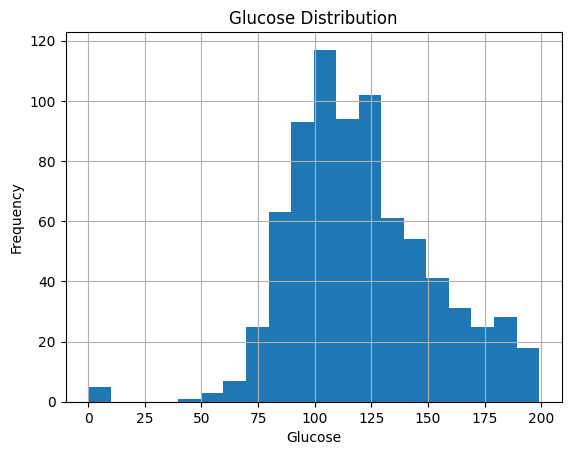

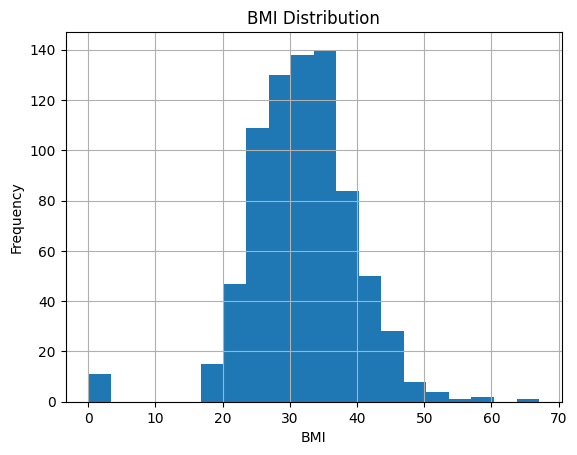

In [41]:
import matplotlib.pyplot as plt

df["Glucose"].hist(bins=20)
plt.title("Glucose Distribution")
plt.xlabel("Glucose")
plt.ylabel("Frequency")
plt.show()

df["BMI"].hist(bins=20)
plt.title("BMI Distribution")
plt.xlabel("BMI")
plt.ylabel("Frequency")
plt.show()

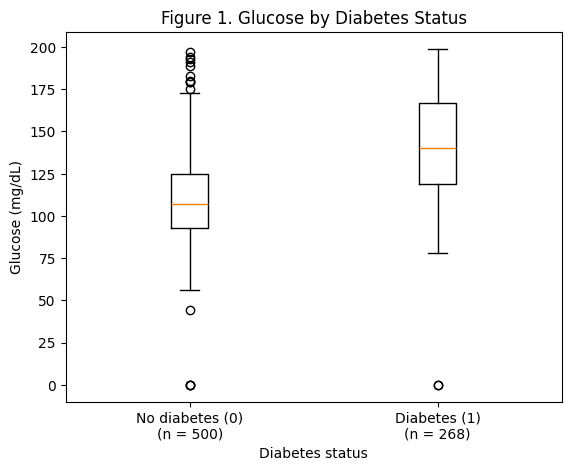

Median glucose: no diabetes = 107, diabetes = 140 mg/dL


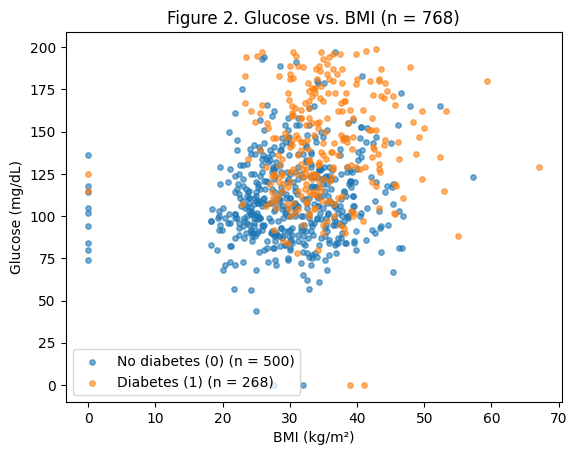

In [42]:
labels = ["No diabetes (0)", "Diabetes (1)"]
glucose_by_group = [df.loc[df["Outcome"] == k, "Glucose"].dropna() for k in (0, 1)]

# Figure 1: box plot of glucose by diabetes status
plt.boxplot(glucose_by_group)
plt.xticks([1, 2], [f"{lab}\n(n = {len(g)})" for lab, g in zip(labels, glucose_by_group)])
plt.title("Figure 1. Glucose by Diabetes Status")
plt.xlabel("Diabetes status")
plt.ylabel("Glucose (mg/dL)")
plt.show()
print("Median glucose: no diabetes = %.0f, diabetes = %.0f mg/dL" % tuple(g.median() for g in glucose_by_group))

# Figure 2: scatter plot of glucose vs BMI, coloured by outcome (patients with both values)
pairs = df[["BMI", "Glucose", "Outcome"]].dropna()
for k, colour in zip((0, 1), ("tab:blue", "tab:orange")):
    sub = pairs[pairs["Outcome"] == k]
    plt.scatter(sub["BMI"], sub["Glucose"], s=15, alpha=0.6, color=colour, label=f"{labels[k]} (n = {len(sub)})")
plt.title(f"Figure 2. Glucose vs. BMI (n = {len(pairs)})")
plt.xlabel("BMI (kg/m²)")
plt.ylabel("Glucose (mg/dL)")
plt.legend()
plt.show()

For the first bivariate plot, patients with diabetes have clearly higher glucose: median **140** vs **107 mg/dL**. The middle halves of the two groups (93–125 vs 119–167 mg/dL) overlap only slightly, but the whiskers overlap, so glucose alone does not separate the groups perfectly.

For the second bivariate plot, glucose and BMI are weakly positively related (higher BMI tends to go with somewhat higher glucose, with a lot of scatter). Patients with diabetes (orange) concentrate in the upper part of the plot: 69 % of patients with glucose of 140 or more have diabetes, compared with 7 % of those below 100. This is a descriptive pattern, not evidence of cause.

***** DATA SCIENCE DIRECTOR NOTE *****

The current visualizations primarily describe individual variables. Please add two appropriate bivariate visualizations to help the receiving data science team better understand relationships between variables in this dataset.

Select variables and visualization types that are appropriate for the data and relevant to the diabetes analysis. At least one of the visualizations should help us examine how a patient characteristic differs in relation to the diabetes outcome.

For each visualization:

• Include a clear, descriptive title and appropriately labeled axes.  
• Select a visualization type that is appropriate for the variables being examined.  
• Include a brief interpretation of the relationship or pattern shown.  
• Refer to the specific variables and findings from this dataset rather than providing a generic description of the visualization.

Please make sure the visualizations and accompanying interpretations are suitable for sharing with the data science team at our other clinical site.

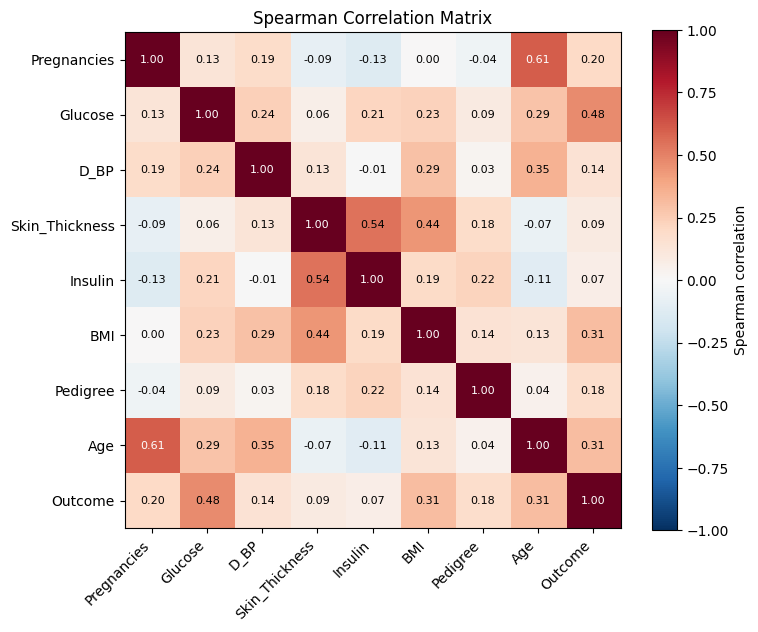

In [43]:
corr = df.corr(method="spearman")   # pairwise-complete observations

fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)))
ax.set_yticks(range(len(corr)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticklabels(corr.index)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.values[i, j]:.2f}", ha="center", va="center", fontsize=8,
                color="white" if abs(corr.values[i, j]) > 0.6 else "black")
fig.colorbar(im, label="Spearman correlation")
ax.set_title("Spearman Correlation Matrix")
plt.show()

This correlation matrix uses Spearman's rank correlation, as several variables are strongly right-skewed with extreme values (`Insulin`, `Pedigree`, `Age`), which makes Pearson's correlation unreliable. Spearman's correlation is Pearson's correlation applied to the ranks of the values, so it is robust to outliers and detects any consistent increasing or decreasing trend. It can also be used with the 0/1 `Outcome`. Each correlation uses the patients who have both values.

Values range from −1 (perfect negative) through 0 (none) to +1 (perfect positive).

In this matrix, we see that for the With diabetes (`Outcome`), `Glucose` has the strongest association (0.48, moderate, positive). `Insulin` (0.38, but only 394 patients), `BMI` (0.31) and `Age` (0.31) are moderate; `Skin_Thickness` (0.27), `Pregnancies` (0.20), `D_BP` (0.18) and `Pedigree` (0.18) are weak.
 For the measurements, `Skin_Thickness`–`BMI` (0.69; both reflect body fat), `Glucose`–`Insulin` (0.66) and `Age`–`Pregnancies` (0.61; older women have had more pregnancies) are strong, so these variables may carry overlapping information.
Correlation does not establish causation. Glucose is also part of how diabetes is diagnosed, so its link with `Outcome` is partly built in.

## Inferential Analysis

The following analysis compares glucose values between the two outcome groups.

In [44]:
from scipy.stats import ttest_ind

group_0 = df.loc[df["Outcome"] == 0, "Glucose"]
group_1 = df.loc[df["Outcome"] == 1, "Glucose"]

t_stat, p_value = ttest_ind(group_0, group_1)
print("t-statistic:", t_stat)
print("p-value:", p_value)

t-statistic: -14.600060005973894
p-value: 8.935431645289912e-43


In [45]:
bmi_data = df.dropna(subset=["BMI"]).copy()
bmi_data["Obese"] = np.where(bmi_data["BMI"] >= 30, "Obese (BMI >= 30)", "Not obese (BMI < 30)")

table = pd.crosstab(bmi_data["Obese"], bmi_data["Outcome"])
table.columns = ["No diabetes (0)", "Diabetes (1)"]
print("Observed counts:")
print(table)
print("\nPercent with diabetes in each group:")
print((table["Diabetes (1)"] / table.sum(axis=1) * 100).round(1))

chi2, p, dof, expected = stats.chi2_contingency(table, correction=False)
odds_ratio = (table.loc["Obese (BMI >= 30)", "Diabetes (1)"] * table.loc["Not obese (BMI < 30)", "No diabetes (0)"]) / \
             (table.loc["Obese (BMI >= 30)", "No diabetes (0)"] * table.loc["Not obese (BMI < 30)", "Diabetes (1)"])
print(f"\nChi-square({dof}) = {chi2:.2f}, p = {p:.1e}")
print(f"Smallest expected count: {expected.min():.1f}")
print(f"Odds ratio = {odds_ratio:.2f}, Cramér's V = {np.sqrt(chi2 / table.values.sum()):.2f}")

Observed counts:
                      No diabetes (0)  Diabetes (1)
Obese                                              
Not obese (BMI < 30)              247            49
Obese (BMI >= 30)                 253           219

Percent with diabetes in each group:
Obese
Not obese (BMI < 30)    16.6
Obese (BMI >= 30)       46.4
dtype: float64

Chi-square(1) = 71.32, p = 3.0e-17
Smallest expected count: 103.3
Odds ratio = 4.36, Cramér's V = 0.30


I also added the chi-square test of independence (obesity and diabetes)
We can use this test to ask: is obesity associated with diabetes status? Patients are grouped as obese (BMI ≥ 30 kg/m²) or not obese (BMI < 30), and the test compares the observed counts in the 2 × 2 table of obesity by diabetes status with the counts expected if the two were unrelated.

$$\chi^2 = \sum_{k=1}^{4} \frac{(O_k - E_k)^2}{E_k}, \qquad E_k = \frac{(\text{row total}) \times (\text{column total})}{N}, \qquad \text{df} = (r-1)(c-1) = 1$$

where $O_k$ and $E_k$ are the observed and expected counts in cell $k$ of the table, $r = c = 2$ are the numbers of rows and columns, and $N$ is the number of patients with a recorded BMI. $H_0$: obesity and diabetes status are independent. A large $\chi^2$ (small $p$-value) means the observed counts differ from those expected under independence. Patients with missing BMI (11) are excluded. All expected counts exceed 5, so the test is appropriate. We also report the **odds ratio and **Cramér's V ($V = \sqrt{\chi^2/N}$; about 0.1 small, 0.3 medium, 0.5 large).

Of the 757 patients with a BMI, 46.4 % of obese patients (219 of 472) have diabetes, compared with 16.5 % of non-obese patients (47 of 285). The association is statistically significant ($\chi^2_1 = 69.7$, $p \approx 7 \times 10^{-17}$); the odds of diabetes are about **4.4 times higher in obese patients (Cramér's $V = 0.30$, a medium association). This is an association in cross-sectional data, not proof that obesity causes diabetes, and it is not adjusted for age or other factors.


## Data, Statistics, and the Machine Learning Workflow

### Formalizing the Statistical and Machine Learning Problem

In supervised machine learning we have observations and their target labels. For this dataset, each observation is one patient, and the data are

$$
\mathcal{D} = \{(x_i,y_i)\}_{i=1}^{n},
\qquad
x_i \in \mathbb{R}^{p},
\qquad
y_i \in \{0,1\},
\qquad
n = 768,\quad p = 8.
$$

where:

- $\mathcal{D}$ is the complete diabetes dataset (`Example Dataset_Diabetes.csv`).
- $n = 768$ is the number of patients (rows), and $i = 1, 2, \ldots, 768$ indexes an individual patient.
- $x_i$ is the feature vector (predictor variables) of the $i^{th}$ patient.
- $p = 8$ is the number of predictor variables: the file has 9 columns, and one of them (`Outcome`) is the target.
- $\mathbb{R}^{8}$ is the 8-dimensional space of possible measurement vectors.
- $y_i$ is the target variable of patient $i$. $\{0,1\}$ shows this is a binary classification problem.

For the diabetes dataset used in this notebook:

$$
x_i =
\begin{bmatrix}
\text{Pregnancies}_i \\
\text{Glucose}_i \\
\text{D BP}_i \\
\text{Skin Thickness}_i \\
\text{Insulin}_i \\
\text{BMI}_i \\
\text{Pedigree}_i \\
\text{Age}_i
\end{bmatrix},
\qquad
y_i = \text{Outcome}_i =
\begin{cases}
1 & \text{patient } i \text{ has diabetes} \\
0 & \text{patient } i \text{ does not have diabetes.}
\end{cases}
$$

In this dataset 268 patients (34.9 %) have $y_i = 1$ and 500 (65.1 %) have $y_i = 0$. After Section 4, some entries of $x_i$ are missing (for example `Insulin` for 374 patients), so any model that needs complete vectors must first handle the missing values, using only the training data to do so.

A machine learning algorithm learns an estimated prediction function from training data:

$$
\hat{f}: \mathbb{R}^{8} \rightarrow \{0,1\},
$$

where $\hat{f}$ ("f-hat") is the **estimate of the unknown relationship between a patient's eight measurements and diabetes status. For a new patient with measurements $x_{\text{new}}$, $\hat{f}(x_{\text{new}})$ is the predicted diabetes status. The objective is to predict accurately for patients **not used in training, for example patients at another clinical site. No predictive model is trained in this notebook.

## Reproducibility Check

In [46]:
# A small participant sample used during review
df.sample(8, random_state=SEED)

,Pregnancies,Glucose,D_BP,Skin_Thickness,Insulin,BMI,Pedigree,Age,Outcome
668,6,98,58,33,190,34.0,0.430,43,0
324,2,112,75,32,0,35.7,0.148,21,0
624,2,108,64,0,0,30.8,0.158,21,0
690,8,107,80,0,0,24.6,0.856,34,0
473,7,136,90,0,0,29.9,0.210,50,0
204,6,103,72,32,190,37.7,0.324,55,0
97,1,71,48,18,76,20.4,0.323,22,0
336,0,117,0,0,0,33.8,0.932,44,0


In [47]:
# Bootstrap estimate used during exploratory review
def bootstrap_mean_ci(values, n_boot=1000, seed=SEED):
    values = np.asarray(values.dropna())
    rng = np.random.default_rng(seed)
    means = [rng.choice(values, size=len(values), replace=True).mean() for _ in range(n_boot)]
    return values.mean(), np.percentile(means, [2.5, 97.5])

mean_bmi, (ci_low, ci_high) = bootstrap_mean_ci(df["BMI"])
print(f"Mean BMI = {mean_bmi:.2f}; bootstrap 95% CI = ({ci_low:.2f}, {ci_high:.2f})")

# Running again with the same seed must give identical numbers
assert bootstrap_mean_ci(df["BMI"])[1].tolist() == [ci_low, ci_high]
print("✔ Repeat run with the same seed gave identical results")

Mean BMI = 31.99; bootstrap 95% CI = (31.43, 32.50)
✔ Repeat run with the same seed gave identical results


## Results and Conclusions

Overall, from this dataset, glucose is the characteristic most strongly associated with diabetes, followed by insulin, BMI and age. Obese patients are about four times as likely (in odds) to have diabetes as non-obese patients.

**Limitations**
* Zeros are assumed to be missing values; `Insulin` and `Skin_Thickness` are missing for many patients, so results involving them are based on fewer patients.
* The data come from one specific population (women aged 21 or older, Pima Indian heritage), so results may not apply to other sites.
* The data are cross-sectional: associations are not causal, and glucose is part of the diagnostic definition of diabetes. Confirm the exact definition of `Outcome` in the source documentation.
* Tests are unadjusted for other variables, and no multiple-testing correction was applied. No predictive model was built or evaluated.